<div dir="rtl" style="text-align: right;">
بخش دوم: شرح مسئله
</div>

<div dir="rtl" style="text-align: right;">
گام اول: شناخت داده و کیفیت آن
</div>

### 1.

In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

names_path = "census-income.names"
train_path = "census-income.data"
test_path = "census-income.test"

with open(names_path, "r", encoding="latin-1") as file:
    lines = file.readlines()

start = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("- 50000")
)

all_columns = []
numeric_features = []
categorical_features = []

for line in lines[start + 1:]:

    line = line.strip()

    if not line or line.startswith("|") or ":" not in line:
        continue

    name, definition = line.split(":", 1)

    name = name.strip()
    definition = definition.strip()

    all_columns.append(name)

    if name == "instance weight":
        continue

    if definition.lower().startswith("continuous"):
        numeric_features.append(name)
    else:
        categorical_features.append(name)

all_columns.append("income")

train_df = pd.read_csv(
    train_path,
    header=None,
    names=all_columns,
    skipinitialspace=True,
    na_values=["?"],
    keep_default_na=False
)

test_df = pd.read_csv(
    test_path,
    header=None,
    names=all_columns,
    skipinitialspace=True,
    na_values=["?"],
    keep_default_na=False
)

for df in [train_df, test_df]:
    object_columns = df.select_dtypes(include="str").columns
    df[object_columns] = df[object_columns].apply(
        lambda col: col.str.strip()
    )

weight_column = "instance weight"
target_column = "income"

feature_columns = [
    col for col in all_columns
    if col not in [weight_column, target_column]
]

print("Training Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

print("\nNumber of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))
print("Number of Input Features:", len(feature_columns))

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Training Shape: (199523, 42)
Test Shape: (99762, 42)

Number of Numerical Features: 7
Number of Categorical Features: 33
Number of Input Features: 40

Numerical Features:
['age', 'wage per hour', 'capital gains', 'capital losses', 'dividends from stocks', 'num persons worked for employer', 'weeks worked in year']

Categorical Features:
['class of worker', 'detailed industry recode', 'detailed occupation recode', 'education', 'enroll in edu inst last wk', 'marital stat', 'major industry code', 'major occupation code', 'race', 'hispanic origin', 'sex', 'member of a labor union', 'reason for unemployment', 'full or part time employment stat', 'tax filer stat', 'region of previous residence', 'state of previous residence', 'detailed household and family stat', 'detailed household summary in household', 'migration code-change in msa', 'migration code-change in reg', 'migration code-move within reg', 'live in this house 1 year ago', 'migration prev res in sunbelt', 'family members under 18',

In [25]:
data_summary = pd.DataFrame({
    "Training Data": [
        train_df.shape[0],
        train_df.shape[1],
        len(numeric_features),
        len(categorical_features),
        weight_column,
        target_column
    ],
    "Test Data": [
        test_df.shape[0],
        test_df.shape[1],
        len(numeric_features),
        len(categorical_features),
        weight_column,
        target_column
    ]
}, index=[
    "Number of Rows",
    "Number of Columns",
    "Numerical Features",
    "Categorical Features",
    "Sample Weight",
    "Target Variable"
])

display(data_summary)


,Training Data,Test Data
Number of Rows,199523,99762
Number of Columns,42,42
Numerical Features,7,7
Categorical Features,33,33
Sample Weight,instance weight,instance weight
Target Variable,income,income


### 2.

In [26]:
for df, dataset_name in [
    (train_df, "Training Data"),
    (test_df, "Test Data")
]:

    missing_report = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage (%)": df.isna().mean() * 100
    })

    missing_report = missing_report.sort_values(
        by="Missing Count",
        ascending=False
    )

    print(f"\n{dataset_name}")
    display(missing_report.round(2))

    print("\nTop 5 Features with Most Missing Values:")
    display(missing_report.head(5).round(2))

    print(
        "\nTotal Missing Values:",
        df.isna().sum().sum()
    )

    print("-" * 60)


Training Data


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,99696,49.97
migration code-change in msa,99696,49.97
migration code-change in reg,99696,49.97
migration code-move within reg,99696,49.97
country of birth father,6713,3.36
country of birth mother,6119,3.07
country of birth self,3393,1.70
state of previous residence,708,0.35
age,0,0.00
class of worker,0,0.00



Top 5 Features with Most Missing Values:


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,99696,49.97
migration code-change in msa,99696,49.97
migration code-change in reg,99696,49.97
migration code-move within reg,99696,49.97
country of birth father,6713,3.36



Total Missing Values: 415717
------------------------------------------------------------

Test Data


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,49946,50.07
migration code-change in msa,49946,50.07
migration code-change in reg,49946,50.07
migration code-move within reg,49946,50.07
country of birth father,3429,3.44
country of birth mother,3072,3.08
country of birth self,1764,1.77
state of previous residence,330,0.33
age,0,0.00
class of worker,0,0.00



Top 5 Features with Most Missing Values:


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,49946,50.07
migration code-change in msa,49946,50.07
migration code-change in reg,49946,50.07
migration code-move within reg,49946,50.07
country of birth father,3429,3.44



Total Missing Values: 208379
------------------------------------------------------------


### 3.

In [27]:
y = train_df[target_column].astype("string").str.strip()

weights = pd.to_numeric(
    train_df[weight_column],
    errors="coerce"
)

class_counts = y.value_counts().sort_index()
class_percentages = class_counts / len(y) * 100

weighted_counts = weights.groupby(y).sum()
weighted_counts = weighted_counts.reindex(class_counts.index)

weighted_percentages = (
    weighted_counts / weights.sum()
) * 100

class_report = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages,
    "Weighted Count": weighted_counts,
    "Weighted Percentage (%)": weighted_percentages
})

display(class_report.round(2))


,Count,Percentage (%),Weighted Count,Weighted Percentage (%)
income,,,,
- 50000.,187141,93.79,3.250046e+08,93.59
50000+.,12382,6.21,2.224125e+07,6.41


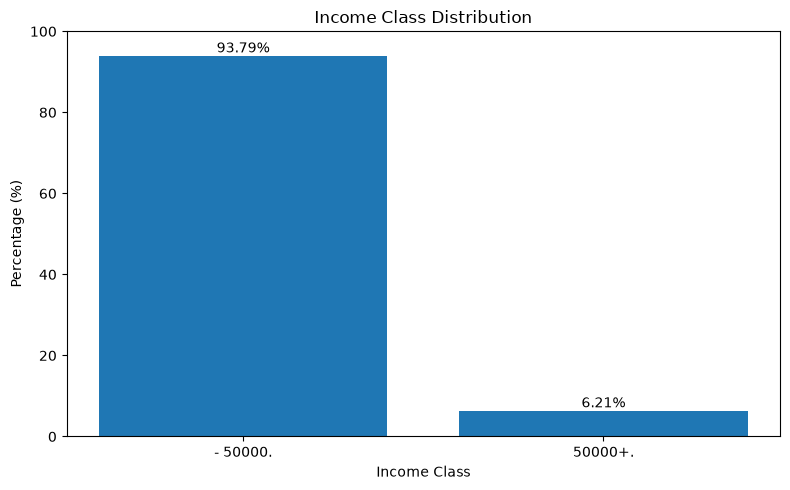

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_percentages.values
)

plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Percentage (%)")

plt.ylim(0, 100)

for i, value in enumerate(class_percentages.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


### 4.

In [32]:
duplicate_mask = train_df.duplicated(keep=False)

duplicate_records = duplicate_mask.sum()

duplicate_groups = (
    train_df.loc[duplicate_mask]
    .drop_duplicates()
    .shape[0]
)

conflict_mask = (
    train_df.groupby(
        feature_columns,
        dropna=False,
        sort=False
    )[target_column]
    .transform("nunique") > 1
)

conflict_records = conflict_mask.sum()

conflict_groups = (
    train_df.loc[conflict_mask, feature_columns]
    .drop_duplicates()
    .shape[0]
)

duplicate_report = pd.DataFrame({
    "Number of Records": [
        duplicate_records,
        conflict_records
    ],
    "Number of Groups": [
        duplicate_groups,
        conflict_groups
    ]
}, index=[
    "Completely Duplicate Records",
    "Same Features, Different Labels"
])

display(duplicate_report)


,Number of Records,Number of Groups
Completely Duplicate Records,5995,2766
"Same Features, Different Labels",379,89


### 5.

In [30]:
not_universe_rows = []

for col in categorical_features:

    values = train_df[col].astype("string")

    count = values.str.contains(
        "Not in universe",
        regex=False,
        na=False
    ).sum()

    missing_count = train_df[col].isna().sum()

    if count > 0:
        not_universe_rows.append({
            "Feature": col,
            "Not in universe Count": count,
            "Missing Count": missing_count,
            "Not in universe Percentage (%)":
                count / len(train_df) * 100
        })

not_universe_report = pd.DataFrame(not_universe_rows)

not_universe_report = not_universe_report.sort_values(
    by="Not in universe Count",
    ascending=False
)

display(not_universe_report.round(2))


,Feature,Not in universe Count,Missing Count,Not in universe Percentage (%)
14,fill inc questionnaire for veteran's admin,197539,0,99.01
5,reason for unemployment,193453,0,96.96
1,enroll in edu inst last wk,186943,0,93.69
7,state of previous residence,183750,708,92.09
6,region of previous residence,183750,0,92.09
4,member of a labor union,180459,0,90.45
13,family members under 18,144232,0,72.29
11,live in this house 1 year ago,101212,0,50.73
2,major industry code,100684,0,50.46
3,major occupation code,100684,0,50.46


<div dir="rtl" style="text-align: right;">
گام دوم: پیش پردازش و مهندسی ویژگی
</div>

In [31]:
def normalize_target(series):

    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", "", regex=True)
        .str.replace(r"\.+$", "", regex=True)
    )

    mapping = {
        "-50000": 0,
        "50000+": 1
    }

    unknown_labels = set(cleaned.dropna().unique()) - set(mapping)

    if unknown_labels:
        raise ValueError(f"Unknown labels found: {unknown_labels}")

    if cleaned.isna().any():
        raise ValueError("Missing target values found!")

    return cleaned.map(mapping).astype("int8")

train_df["income"] = normalize_target(train_df["income"])
test_df["income"] = normalize_target(test_df["income"])

print("Training Target Distribution:")
display(train_df["income"].value_counts())

print("\nTest Target Distribution:")
display(test_df["income"].value_counts())


Training Target Distribution:


income
0    187141
1     12382
Name: count, dtype: int64


Test Target Distribution:


income
0    93576
1     6186
Name: count, dtype: int64

### 2.

In [35]:
target_column = "income"
weight_column = "instance weight"

feature_columns = numeric_features + categorical_features

feature_table = pd.DataFrame({
    "Feature": feature_columns,
    "Type": [
        "Numerical" if col in numeric_features else "Categorical"
        for col in feature_columns
    ]
})

display(feature_table)

print("Total Input Features:", len(feature_columns))
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))


,Feature,Type
0,age,Numerical
1,wage per hour,Numerical
2,capital gains,Numerical
3,capital losses,Numerical
4,dividends from stocks,Numerical
5,num persons worked for employer,Numerical
6,weeks worked in year,Numerical
7,class of worker,Categorical
8,detailed industry recode,Categorical
9,detailed occupation recode,Categorical


Total Input Features: 40
Numerical Features: 7
Categorical Features: 33


### 3,4,5

In [ ]:
from sklearn.model_selection import train_test_split

train_sample = train_df.sample(
    n=10000,
    random_state=42
).copy()

test_sample = test_df.sample(
    n=2000,
    random_state=43
).copy()

X = train_sample[feature_columns].copy()
y = train_sample[target_column].copy()

X_test = test_sample[feature_columns].copy()
y_test = test_sample[target_column].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)




Training: (8000, 40)
Validation: (2000, 40)
Test: (2000, 40)


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [38]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed!")


Preprocessing Completed!
